In [ ]:
import pandas as pd
import numpy as np

# Sesuaikan nama file dan ekstensi dengan file yang kamu upload di Colab!
# Jika file berformat Excel (.xls atau .xlsx) dari Tableau Public:
df = pd.read_excel('sample_superstore.xls', sheet_name='Orders')

# Jika file berformat CSV (.csv), beri tanda # pada baris di atas dan aktifkan baris di bawah ini:
# df = pd.read_csv('Sample - Superstore.csv', encoding='windows-1252')

# Menampilkan 5 baris pertama untuk memastikan data terbaca dengan rapi
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [ ]:
# 1. Cek dimensi dataset (jumlah baris, jumlah kolom)
print(f"Dimensi Dataset: {df.shape[0]} baris dan {df.shape[1]} kolom\n")

# 2. Cek nama kolom, jumlah data non-null, dan tipe data setiap kolom
print("--- INFORMASI STRUKTUR DATA ---")
df.info()

Dimensi Dataset: 10194 baris dan 21 kolom

--- INFORMASI STRUKTUR DATA ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  object        
 2   Order Date      10194 non-null  datetime64[ns]
 3   Ship Date       10194 non-null  datetime64[ns]
 4   Ship Mode       10194 non-null  object        
 5   Customer ID     10194 non-null  object        
 6   Customer Name   10194 non-null  object        
 7   Segment         10194 non-null  object        
 8   Country/Region  10194 non-null  object        
 9   City            10194 non-null  object        
 10  State/Province  10194 non-null  object        
 11  Postal Code     10194 non-null  object        
 12  Region          10194 non-null  object        
 13  Product ID      10194 non-null 

In [ ]:
# Memisahkan kolom numerik dan kategorikal
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
date_cols = df.select_dtypes(include=['datetime64[ns]']).columns.tolist()

print("Kolom Numerik:", numerical_cols)
print("\nKolom Kategorikal:", categorical_cols)
print("\nKolom Tanggal:", date_cols)

Kolom Numerik: ['Row ID', 'Sales', 'Quantity', 'Discount', 'Profit']

Kolom Kategorikal: ['Order ID', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name']

Kolom Tanggal: ['Order Date', 'Ship Date']


In [ ]:
# Membuat salinan dataframe agar data mentah tetap aman (Best Practice!)
df_clean = df.copy()

# 1. Cek missing values standar (NaN)
print("--- 1. MISSING VALUES (NaN) ---")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

# 2. Cek string kosong atau hanya berisi spasi pada kolom teks
print("\n--- 2. STRING KOSONG / SPASI ---")
for col in df_clean.select_dtypes(include='object').columns:
    empty_count = df_clean[col].astype(str).str.strip().eq('').sum()
    if empty_count > 0:
        print(f"Kolom '{col}' memiliki {empty_count} string kosong.")

# 3. Cek duplikat persis seluruh kolom (kecuali Row ID)
cols_without_rowid = [col for col in df_clean.columns if col != 'Row ID']
exact_dups = df_clean.duplicated(subset=cols_without_rowid).sum()
print(f"\n--- 3. EXACT DUPLICATES (Tanpa Row ID) ---")
print(f"Jumlah baris duplikat identik: {exact_dups}")

# Jika ada duplikat, tampilkan barisnya untuk diperiksa sebelum dihapus!
if exact_dups > 0:
    display(df_clean[df_clean.duplicated(subset=cols_without_rowid, keep=False)])

--- 1. MISSING VALUES (NaN) ---
Series([], dtype: int64)

--- 2. STRING KOSONG / SPASI ---

--- 3. EXACT DUPLICATES (Tanpa Row ID) ---
Jumlah baris duplikat identik: 2


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
390,391,US-2023-150119,2023-04-23,2023-04-27,Standard Class,LB-16795,Laurel Beltran,Home Office,United States,Columbus,...,43229,East,FUR-CH-10002965,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.372,2,0.3,-12.0588
391,392,US-2023-150119,2023-04-23,2023-04-27,Standard Class,LB-16795,Laurel Beltran,Home Office,United States,Columbus,...,43229,East,FUR-CH-10002965,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.372,2,0.3,-12.0588
1698,1699,CA-2023-153623,2023-11-24,2023-12-05,Standard Class,JP-11135,James Peterman,Corporate,Canada,St. John's,...,A0A,East,FUR-FU-10002501,Furniture,Furnishings,Nu-Dell Executive Frame,99.120,8,0.0,35.4144
1699,1700,CA-2023-153623,2023-11-24,2023-12-05,Standard Class,JP-11135,James Peterman,Corporate,Canada,St. John's,...,A0A,East,FUR-FU-10002501,Furniture,Furnishings,Nu-Dell Executive Frame,99.120,8,0.0,35.4144


In [ ]:
# 1. Cek nilai unik pada kolom kategorikal utama (apakah ada typo / spasi ganda?)
check_cols = ['Ship Mode', 'Segment', 'Country/Region', 'Region', 'Category', 'Sub-Category']
print("--- 1. AUDIT KONSISTENSI KATEGORI ---")
for col in check_cols:
    print(f"{col} ({df_clean[col].nunique()} unik): {df_clean[col].unique().tolist()}")

# 2. Cek Anomali Tanggal (Ship Date lebih awal dari Order Date?)
invalid_dates = df_clean[df_clean['Ship Date'] < df_clean['Order Date']]
print(f"\n--- 2. ANOMALI TANGGAL PENGIRIMAN ---")
print(f"Jumlah transaksi dengan Ship Date < Order Date: {len(invalid_dates)}")

# 3. Cek Anomali Angka (Sales <= 0, Quantity <= 0, atau Discount di luar 0 - 1)
print(f"\n--- 3. ANOMALI NUMERIK ---")
print(f"Sales <= 0     : {(df_clean['Sales'] <= 0).sum()} baris")
print(f"Quantity <= 0  : {(df_clean['Quantity'] <= 0).sum()} baris")
print(f"Discount < 0   : {(df_clean['Discount'] < 0).sum()} baris")
print(f"Discount > 1   : {(df_clean['Discount'] > 1).sum()} baris")
print(f"Profit < 0     : {(df_clean['Profit'] < 0).sum()} baris (Transaksi Rugi - Sah untuk dianalisis)")

--- 1. AUDIT KONSISTENSI KATEGORI ---
Ship Mode (4 unik): ['Standard Class', 'First Class', 'Second Class', 'Same Day']
Segment (3 unik): ['Consumer', 'Home Office', 'Corporate']
Country/Region (2 unik): ['United States', 'Canada']
Region (4 unik): ['Central', 'East', 'South', 'West']
Category (3 unik): ['Office Supplies', 'Furniture', 'Technology']
Sub-Category (17 unik): ['Paper', 'Binders', 'Labels', 'Storage', 'Art', 'Chairs', 'Fasteners', 'Phones', 'Furnishings', 'Accessories', 'Bookcases', 'Envelopes', 'Appliances', 'Tables', 'Supplies', 'Machines', 'Copiers']

--- 2. ANOMALI TANGGAL PENGIRIMAN ---
Jumlah transaksi dengan Ship Date < Order Date: 0

--- 3. ANOMALI NUMERIK ---
Sales <= 0     : 0 baris
Quantity <= 0  : 0 baris
Discount < 0   : 0 baris
Discount > 1   : 0 baris
Profit < 0     : 1901 baris (Transaksi Rugi - Sah untuk dianalisis)


In [ ]:
# 1. Bersihkan spasi berlebih (whitespace) di awal/akhir pada semua kolom teks
for col in df_clean.select_dtypes(include='object').columns:
    df_clean[col] = df_clean[col].astype(str).str.strip()

# 2. Feature Engineering: Ekstrak komponen waktu & metrik bisnis
df_clean['Order Year'] = df_clean['Order Date'].dt.year
df_clean['Order Month'] = df_clean['Order Date'].dt.month
df_clean['Order Month-Year'] = df_clean['Order Date'].dt.to_period('M').astype(str)
df_clean['Shipping Days'] = (df_clean['Ship Date'] - df_clean['Order Date']).dt.days
df_clean['Profit Margin (%)'] = (df_clean['Profit'] / df_clean['Sales']) * 100

# Verifikasi hasil kolom baru
df_clean[['Order Date', 'Ship Date', 'Shipping Days', 'Sales', 'Profit', 'Profit Margin (%)']].head()

,Order Date,Ship Date,Shipping Days,Sales,Profit,Profit Margin (%)
0,2023-01-03,2023-01-07,4,16.448,5.5512,33.75
1,2023-01-04,2023-01-08,4,3.540,-5.4870,-155.00
2,2023-01-04,2023-01-08,4,11.784,4.2717,36.25
3,2023-01-04,2023-01-08,4,272.736,-64.7748,-23.75
4,2023-01-05,2023-01-12,7,19.536,4.8840,25.00


In [ ]:
# Menghapus 2 baris duplikat identik (mempertahankan kemunculan pertama)
df_clean = df_clean.drop_duplicates(subset=cols_without_rowid, keep='first').reset_index(drop=True)
print(f"Jumlah baris setelah deduplikasi: {len(df_clean)} baris")

Jumlah baris setelah deduplikasi: 10192 baris


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur tema visualisasi agar rapi dan profesional
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# 1. Menghitung KPI Utama Perusahaan
total_sales = df_clean['Sales'].sum()
total_profit = df_clean['Profit'].sum()
overall_margin = (total_profit / total_sales) * 100
total_orders = df_clean['Order ID'].nunique()
total_qty = df_clean['Quantity'].sum()
aov = total_sales / total_orders

print("=== RINGKASAN KPI UTAMA PERUSAHAAN ===")
print(f"Total Sales (Revenue) : ${total_sales:,.2f}")
print(f"Total Profit          : ${total_profit:,.2f}")
print(f"Overall Profit Margin : {overall_margin:.2f}%")
print(f"Total Unique Orders   : {total_orders:,} transaksi")
print(f"Total Quantity Sold   : {total_qty:,} unit")
print(f"Average Order Value   : ${aov:,.2f}")

# 2. Statistik Deskriptif untuk variabel numerik utama
print("\n=== STATISTIK DESKRIPTIF TRANSAKSI ===")
display(df_clean[['Sales', 'Quantity', 'Discount', 'Profit', 'Shipping Days']].describe().round(2))

=== RINGKASAN KPI UTAMA PERUSAHAAN ===
Total Sales (Revenue) : $2,326,153.86
Total Profit          : $292,273.46
Overall Profit Margin : 12.56%
Total Unique Orders   : 5,111 transaksi
Total Quantity Sold   : 38,644 unit
Average Order Value   : $455.13

=== STATISTIK DESKRIPTIF TRANSAKSI ===


,Sales,Quantity,Discount,Profit,Shipping Days
count,10192.00,10192.00,10192.00,10192.00,10192.00
mean,228.23,3.79,0.16,28.68,3.96
std,619.97,2.23,0.21,232.49,1.74
min,0.44,1.00,0.00,-6599.98,0.00
25%,17.22,2.00,0.00,1.76,3.00
50%,53.89,3.00,0.20,8.69,4.00
75%,209.50,5.00,0.20,29.29,5.00
max,22638.48,14.00,0.80,8399.98,11.00


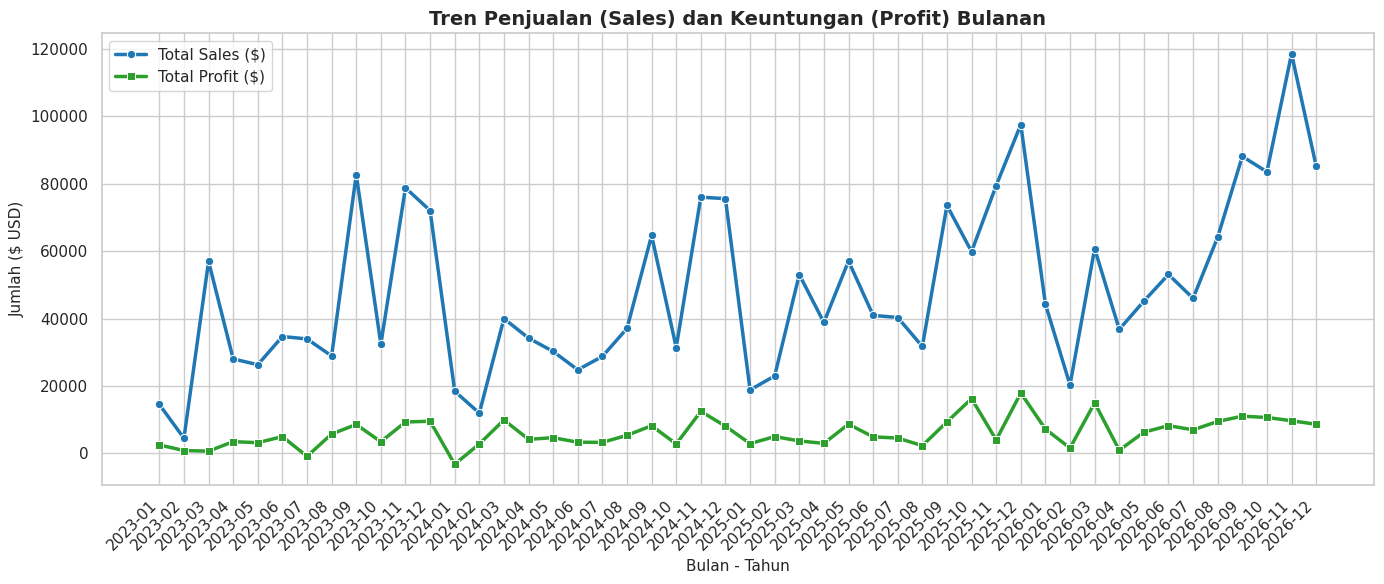

,Order Year,Total_Sales,Total_Profit,Total_Orders,Profit_Margin (%)
0,2023,493659.72,51660.94,995,10.46
1,2024,472993.03,62020.97,1053,13.11
2,2025,613933.58,82665.20,1340,13.46
3,2026,745567.53,95926.35,1723,12.87


In [ ]:
# Agregasi Sales dan Profit berdasarkan Bulan-Tahun
monthly_trend = df_clean.groupby('Order Month-Year')[['Sales', 'Profit']].sum().reset_index()

# Visualisasi Line Chart Tren Bulanan
fig, ax = plt.subplots(figsize=(14, 6))
sns.lineplot(data=monthly_trend, x='Order Month-Year', y='Sales', marker='o', label='Total Sales ($)', linewidth=2.5, color='#1f77b4')
sns.lineplot(data=monthly_trend, x='Order Month-Year', y='Profit', marker='s', label='Total Profit ($)', linewidth=2.5, color='#2ca02c')

plt.title('Tren Penjualan (Sales) dan Keuntungan (Profit) Bulanan', fontsize=14, fontweight='bold')
plt.xlabel('Bulan - Tahun', fontsize=11)
plt.ylabel('Jumlah ($ USD)', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.show()

# Tabel Ringkasan Tahunan (YoY Performance)
yearly_summary = df_clean.groupby('Order Year').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Orders=('Order ID', 'nunique')
).reset_index()
yearly_summary['Profit_Margin (%)'] = (yearly_summary['Total_Profit'] / yearly_summary['Total_Sales']) * 100
display(yearly_summary.round(2))

=== PERFORMA PER KATEGORI ===


,Category,Total_Sales,Total_Profit,Total_Qty,Profit_Margin (%)
2,Technology,839893.28,146543.38,7017,17.45
0,Furniture,754367.27,19706.64,8359,2.61
1,Office Supplies,731893.31,126023.44,23268,17.22


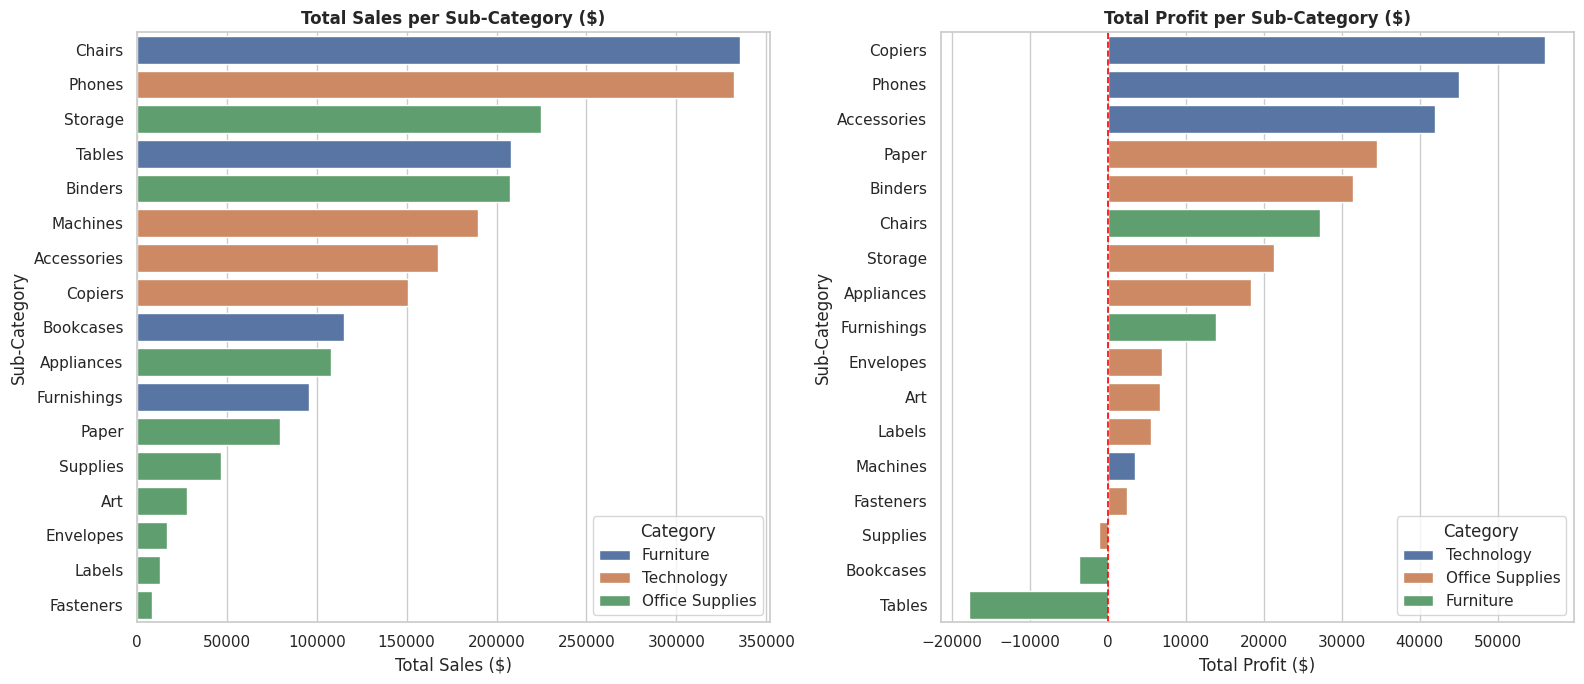

In [ ]:
# 1. Ringkasan per Category
cat_summary = df_clean.groupby('Category').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Qty=('Quantity', 'sum')
).reset_index().sort_values(by='Total_Sales', ascending=False)
cat_summary['Profit_Margin (%)'] = (cat_summary['Total_Profit'] / cat_summary['Total_Sales']) * 100

print("=== PERFORMA PER KATEGORI ===")
display(cat_summary.round(2))

# 2. Ringkasan per Sub-Category (Diurutkan berdasarkan Profit)
subcat_summary = df_clean.groupby(['Category', 'Sub-Category']).agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Avg_Discount=('Discount', 'mean')
).reset_index().sort_values(by='Total_Profit', ascending=False)
subcat_summary['Profit_Margin (%)'] = (subcat_summary['Total_Profit'] / subcat_summary['Total_Sales']) * 100

# Visualisasi Horizontal Bar Chart untuk Sub-Category (Sales vs Profit)
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Grafik Kiri: Total Sales per Sub-Category
sns.barplot(data=subcat_summary.sort_values('Total_Sales', ascending=False),
            x='Total_Sales', y='Sub-Category', hue='Category', dodge=False, ax=axes[0])
axes[0].set_title('Total Sales per Sub-Category ($)', fontweight='bold')
axes[0].set_xlabel('Total Sales ($)')

# Grafik Kanan: Total Profit per Sub-Category
sns.barplot(data=subcat_summary,
            x='Total_Profit', y='Sub-Category', hue='Category', dodge=False, ax=axes[1])
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.2) # Garis batas rugi (0)
axes[1].set_title('Total Profit per Sub-Category ($)', fontweight='bold')
axes[1].set_xlabel('Total Profit ($)')

plt.tight_layout()
plt.show()

In [ ]:
# 1. Performa berdasarkan Region
region_summary = df_clean.groupby('Region').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Orders=('Order ID', 'nunique'),
    Avg_Discount=('Discount', 'mean')
).reset_index().sort_values(by='Total_Sales', ascending=False)
region_summary['Profit_Margin (%)'] = (region_summary['Total_Profit'] / region_summary['Total_Sales']) * 100

print("=== PERFORMA BERDASARKAN REGION ===")
display(region_summary.round(2))

# 2. Top 5 State/Province Paling Untung vs Top 5 Paling Rugi
state_summary = df_clean.groupby(['Country/Region', 'State/Province']).agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Avg_Discount=('Discount', 'mean')
).reset_index()

print("\n=== TOP 5 STATE/PROVINCE PALING UNTUNG ===")
display(state_summary.sort_values(by='Total_Profit', ascending=False).head(5).round(2))

print("\n=== TOP 5 STATE/PROVINCE PALING RUGI ===")
display(state_summary.sort_values(by='Total_Profit', ascending=True).head(5).round(2))

=== PERFORMA BERDASARKAN REGION ===


,Region,Total_Sales,Total_Profit,Total_Orders,Avg_Discount,Profit_Margin (%)
3,West,739813.61,110798.82,1635,0.11,14.98
1,East,691447.68,94859.90,1475,0.14,13.72
0,Central,503170.67,39865.31,1179,0.24,7.92
2,South,391721.90,46749.43,822,0.15,11.93



=== TOP 5 STATE/PROVINCE PALING UNTUNG ===


,Country/Region,State/Province,Total_Sales,Total_Profit,Avg_Discount
13,United States,California,457687.63,76381.39,0.07
40,United States,New York,310876.27,74038.55,0.06
55,United States,Washington,138641.27,33402.65,0.06
30,United States,Michigan,76269.61,24463.19,0.01
54,United States,Virginia,70636.72,18597.95,0.00



=== TOP 5 STATE/PROVINCE PALING RUGI ===


,Country/Region,State/Province,Total_Sales,Total_Profit,Avg_Discount
51,United States,Texas,170188.05,-25729.36,0.37
43,United States,Ohio,77976.76,-16959.32,0.32
46,United States,Pennsylvania,116511.91,-15559.96,0.33
21,United States,Illinois,80166.10,-12607.89,0.39
41,United States,North Carolina,55603.16,-7490.91,0.28


In [ ]:
# 1. Performa per Customer Segment
segment_summary = df_clean.groupby('Segment').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Customers=('Customer ID', 'nunique'),
    Total_Orders=('Order ID', 'nunique')
).reset_index().sort_values(by='Total_Sales', ascending=False)
segment_summary['Profit_Margin (%)'] = (segment_summary['Total_Profit'] / segment_summary['Total_Sales']) * 100

print("=== PERFORMA PER SEGMEN PELANGGAN ===")
display(segment_summary.round(2))

# 2. Top 10 Produk berdasarkan Total Sales
top_products = df_clean.groupby(['Category', 'Sub-Category', 'Product Name']).agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Qty=('Quantity', 'sum')
).reset_index().sort_values(by='Total_Sales', ascending=False).head(10)

print("\n=== TOP 10 PRODUK DENGAN PENJUALAN TERTINGGI ===")
display(top_products.round(2))

=== PERFORMA PER SEGMEN PELANGGAN ===


,Segment,Total_Sales,Total_Profit,Total_Customers,Total_Orders,Profit_Margin (%)
0,Consumer,1170659.79,136371.45,416,2628,11.65
1,Corporate,715707.01,94214.23,239,1552,13.16
2,Home Office,439787.06,61687.79,149,931,14.03



=== TOP 10 PRODUK DENGAN PENJUALAN TERTINGGI ===


,Category,Sub-Category,Product Name,Total_Sales,Total_Profit,Total_Qty
1591,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,61599.82,25199.93,20
715,Office Supplies,Binders,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.38,7753.04,31
1611,Technology,Machines,Cisco TelePresence System EX90 Videoconferenci...,22638.48,-1811.08,6
90,Furniture,Chairs,HON 5400 Series Task Chairs for Big and Tall,21870.58,0.00,39
727,Office Supplies,Binders,GBC DocuBind TL300 Electric Binding System,19823.48,2233.51,37
729,Office Supplies,Binders,GBC Ibimaster 500 Manual ProClick Binding System,19024.50,760.98,48
1594,Technology,Copiers,Hewlett Packard LaserJet 3310 Copier,18839.69,6983.88,38
1619,Technology,Machines,HP Designjet T520 Inkjet Large Format Printer ...,18374.90,4094.98,12
724,Office Supplies,Binders,GBC DocuBind P400 Electric Binding System,17965.07,-1878.17,27
1427,Office Supplies,Supplies,High Speed Automatic Electric Letter Opener,17030.31,-262.00,11


=== DAMPAK TINGKAT DISKON TERHADAP PROFIT ===


,Discount,Jumlah_Transaksi,Total_Sales,Total_Profit,Avg_Profit_Per_Transaksi
0,0.00,4924,1105224.67,326683.17,66.35
1,0.10,96,54952.50,9099.97,94.79
2,0.15,52,27558.52,1418.99,27.29
3,0.20,3706,773939.40,91079.95,24.58
4,0.30,229,104192.70,-10501.39,-45.86
5,0.32,27,14493.46,-2391.14,-88.56
6,0.40,207,116497.76,-23086.37,-111.53
7,0.45,11,5484.97,-2493.11,-226.65
8,0.50,66,58918.54,-20506.43,-310.70
9,0.60,149,7105.94,-6164.35,-41.37


/tmp/ipykernel_2484/817584267.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=discount_impact, x='Discount', y='Avg_Profit_Per_Transaksi', palette='RdYlGn', ax=axes[0])


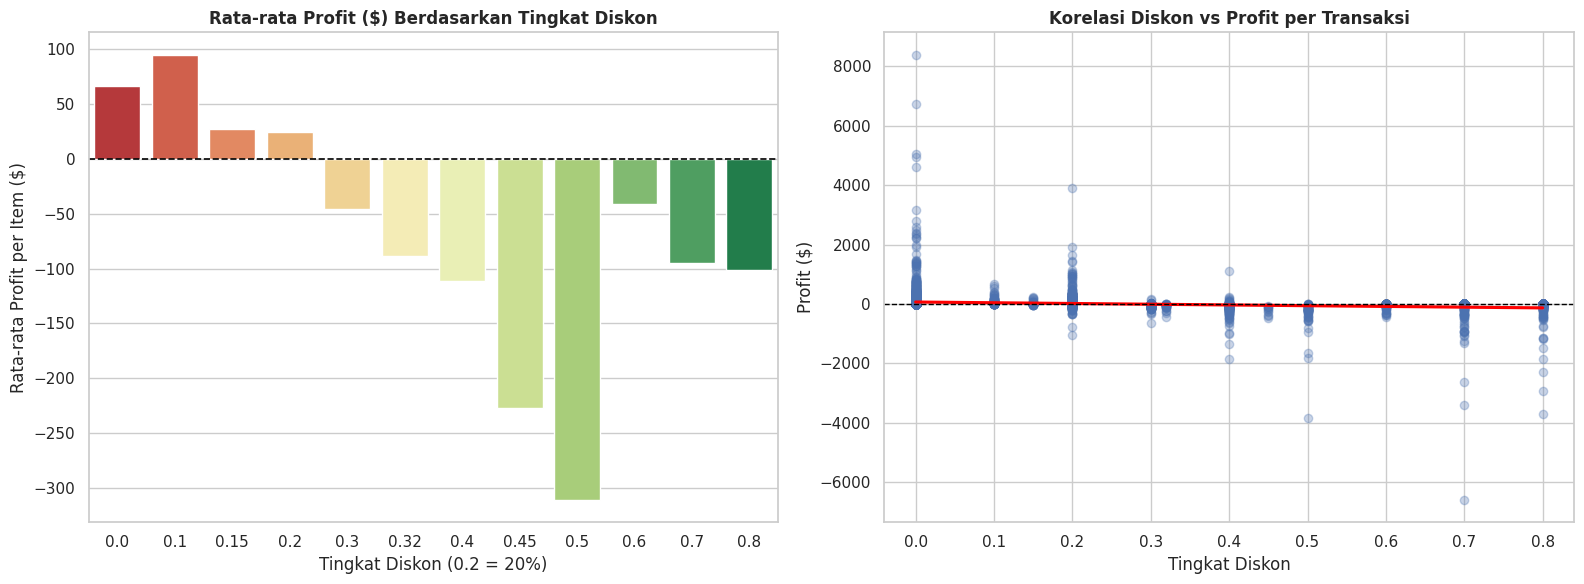

Koefisien Korelasi (Pearson) antara Discount dan Profit: -0.2189


In [ ]:
# 1. Agregasi Profit berdasarkan Tingkat Diskon
discount_impact = df_clean.groupby('Discount').agg(
    Jumlah_Transaksi=('Row ID', 'count'),
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Avg_Profit_Per_Transaksi=('Profit', 'mean')
).reset_index()

print("=== DAMPAK TINGKAT DISKON TERHADAP PROFIT ===")
display(discount_impact.round(2))

# 2. Visualisasi Hubungan Diskon vs Rata-rata Profit & Korelasi
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Grafik Kiri: Barplot Rata-rata Profit per Tingkat Diskon
sns.barplot(data=discount_impact, x='Discount', y='Avg_Profit_Per_Transaksi', palette='RdYlGn', ax=axes[0])
axes[0].axhline(0, color='black', linestyle='--', linewidth=1.2)
axes[0].set_title('Rata-rata Profit ($) Berdasarkan Tingkat Diskon', fontweight='bold')
axes[0].set_xlabel('Tingkat Diskon (0.2 = 20%)')
axes[0].set_ylabel('Rata-rata Profit per Item ($)')

# Grafik Kanan: Regplot / Trendline Diskon vs Profit
sns.regplot(data=df_clean, x='Discount', y='Profit', scatter_kws={'alpha':0.3}, line_kws={'color':'red'}, ax=axes[1])
axes[1].axhline(0, color='black', linestyle='--', linewidth=1)
axes[1].set_title('Korelasi Diskon vs Profit per Transaksi', fontweight='bold')
axes[1].set_xlabel('Tingkat Diskon')
axes[1].set_ylabel('Profit ($)')

plt.tight_layout()
plt.show()

# Cek korelasi numerik Pearson antara Discount dan Profit
corr_val = df_clean['Discount'].corr(df_clean['Profit'])
print(f"Koefisien Korelasi (Pearson) antara Discount dan Profit: {corr_val:.4f}")

In [ ]:
# Memfilter sub-kategori yang rugi (Total_Profit < 0)
subcat_rugi = subcat_summary[subcat_summary['Total_Profit'] < 0]
display(subcat_rugi.round(2))

,Category,Sub-Category,Total_Sales,Total_Profit,Avg_Discount,Profit_Margin (%)
12,Office Supplies,Supplies,46725.50,-1171.39,0.08,-2.51
0,Furniture,Bookcases,115361.20,-3632.07,0.22,-3.15
3,Furniture,Tables,208020.18,-17753.21,0.26,-8.53


In [ ]:
# 1. Pastikan format tanggal bersih (YYYY-MM-DD) agar dikenali otomatis oleh Google Sheets & Looker Studio
df_export = df_clean.copy()
df_export['Order Date'] = df_export['Order Date'].dt.strftime('%Y-%m-%d')
df_export['Ship Date'] = df_export['Ship Date'].dt.strftime('%Y-%m-%d')

# 2. Export ke file CSV tanpa menyertakan index Pandas (index=False)
output_filename = 'superstore_cleaned_final.csv'
df_export.to_csv(output_filename, index=False)

print(f"Berhasil mengekspor {len(df_export)} baris dan {len(df_export.columns)} kolom ke '{output_filename}'!")

Berhasil mengekspor 10192 baris dan 26 kolom ke 'superstore_cleaned_final.csv'!
